<a href="https://colab.research.google.com/github/AkashDAVLabs/DAV-lab-programs/blob/main/Feature_Engineering_Normalization_Standardization_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA


## 1. Create and inspect the different dataset

In [3]:
data = {
    "Study_Hours": [1, 3, 5, 7, 9, 2, 4, 6, 8, 11, 12, 10],
    "Attendance": [52, 61, 67, 74, 82, 58, 65, 71, 88, 91, 97, 85],
    "Assignment_Score": [35, 48, 54, 63, 76, 42, 57, 68, 79, 86, 94, 81],
    "Exam_Score": [38, 46, 56, 62, 73, 43, 53, 66, 78, 89, 96, 80],
}
df = pd.DataFrame(data)

print("Original Dataset:")
display(df)
print("\\nStatistical Summary:")
display(df.describe())


Original Dataset:


,Study_Hours,Attendance,Assignment_Score,Exam_Score
0,1,52,35,38
1,3,61,48,46
2,5,67,54,56
3,7,74,63,62
4,9,82,76,73
5,2,58,42,43
6,4,65,57,53
7,6,71,68,66
8,8,88,79,78
9,11,91,86,89


\nStatistical Summary:


,Study_Hours,Attendance,Assignment_Score,Exam_Score
count,12.000000,12.000000,12.000000,12.000000
mean,6.500000,74.250000,65.250000,65.000000
std,3.605551,14.290016,18.513509,18.596187
min,1.000000,52.000000,35.000000,38.000000
25%,3.750000,64.000000,52.500000,51.250000
50%,6.500000,72.500000,65.500000,64.000000
75%,9.250000,85.750000,79.500000,78.500000
max,12.000000,97.000000,94.000000,96.000000


## 2. Normalization using MinMaxScaler

In [4]:
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(df)
normalized_df = pd.DataFrame(normalized_data, columns=df.columns)

print("Normalized Dataset:")
display(normalized_df.round(2))
print("\\nMinimum values:")
display(normalized_df.min().round(2))
print("\\nMaximum values:")
display(normalized_df.max().round(2))


Normalized Dataset:


,Study_Hours,Attendance,Assignment_Score,Exam_Score
0,0.00,0.00,0.00,0.00
1,0.18,0.20,0.22,0.14
2,0.36,0.33,0.32,0.31
3,0.55,0.49,0.47,0.41
4,0.73,0.67,0.69,0.60
5,0.09,0.13,0.12,0.09
6,0.27,0.29,0.37,0.26
7,0.45,0.42,0.56,0.48
8,0.64,0.80,0.75,0.69
9,0.91,0.87,0.86,0.88


\nMinimum values:


,0
Study_Hours,0.0
Attendance,0.0
Assignment_Score,0.0
Exam_Score,0.0


\nMaximum values:


,0
Study_Hours,1.0
Attendance,1.0
Assignment_Score,1.0
Exam_Score,1.0


## 3. Standardization using StandardScaler

In [5]:
scaler = StandardScaler()
standardized_data = scaler.fit_transform(df)
standardized_df = pd.DataFrame(standardized_data, columns=df.columns)

print("Standardized Dataset:")
display(standardized_df.round(2))
print("\\nMean of each feature:")
display(standardized_df.mean().round(2))
print("\\nStandard deviation of each feature (ddof=0):")
display(standardized_df.std(ddof=0).round(2))


Standardized Dataset:


,Study_Hours,Attendance,Assignment_Score,Exam_Score
0,-1.59,-1.63,-1.71,-1.52
1,-1.01,-0.97,-0.97,-1.07
2,-0.43,-0.53,-0.63,-0.51
3,0.14,-0.02,-0.13,-0.17
4,0.72,0.57,0.61,0.45
5,-1.30,-1.19,-1.31,-1.24
6,-0.72,-0.68,-0.47,-0.67
7,-0.14,-0.24,0.16,0.06
8,0.43,1.00,0.78,0.73
9,1.30,1.22,1.17,1.35


\nMean of each feature:


,0
Study_Hours,0.0
Attendance,-0.0
Assignment_Score,0.0
Exam_Score,0.0


\nStandard deviation of each feature (ddof=0):


,0
Study_Hours,1.0
Attendance,1.0
Assignment_Score,1.0
Exam_Score,1.0


## 4. PCA for dimensionality reduction (4 features → 2 components)

PCA Transformed Data:


,PC1,PC2
0,-3.22,0.03
1,-2.01,-0.02
2,-1.05,0.11
3,-0.08,0.20
4,1.17,0.15
5,-2.52,-0.06
6,-1.27,-0.11
7,-0.09,-0.09
8,1.47,-0.37
9,2.52,0.07


\nExplained Variance Ratio:
[0.98927816 0.00552181]
\nTotal Variance Retained:
0.9947999662398375


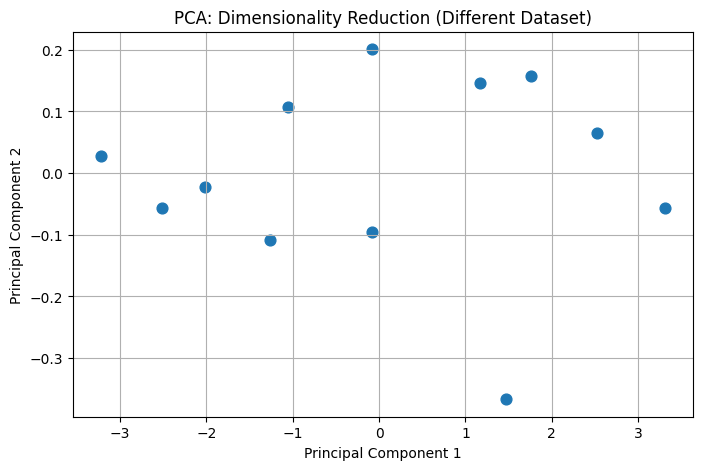

In [6]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)
pca_df = pd.DataFrame(pca_data, columns=["PC1", "PC2"])

print("PCA Transformed Data:")
display(pca_df.round(2))
print("\\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)
print("\\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 5))
plt.scatter(pca_df["PC1"], pca_df["PC2"], s=60)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Dimensionality Reduction (Different Dataset)")
plt.grid(True)
plt.show()


## 5. Save transformed outputs

In [7]:
normalized_df.to_csv("different_normalized_dataset.csv", index=False)
standardized_df.to_csv("different_standardized_dataset.csv", index=False)
pca_df.to_csv("different_pca_2_components.csv", index=False)
print("Saved normalized, standardized, and PCA output CSV files.")


Saved normalized, standardized, and PCA output CSV files.
